In [2]:
from pathlib import Path
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pl.Config.set_tbl_cols(15)
pl.Config.set_tbl_width_chars(160)

# Plot styling for report-ready figures
plt.rcParams["figure.figsize"] = (14, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
sns.set_palette("deep")

DATA_DIR = Path("data")
parquet_files = sorted(DATA_DIR.glob("*.parquet"))
print(f"Found {len(parquet_files)} total parquet files under {DATA_DIR}/")

# Filter out tiny reconnect fragments (< 500 rows) and tag each valid file with a chunk_id
MIN_ROWS = 500
valid_dfs = []
skipped_fragments = 0

for chunk_id, fp in enumerate(parquet_files):
    df_chunk = pl.read_parquet(fp)
    if df_chunk.height < MIN_ROWS:
        skipped_fragments += 1
        continue
    
    # Extract base contract name (CONTROLS-2026, SENATETX-26, SENATEGA-26) and party (-D or -R)
    df_chunk = df_chunk.with_columns([
        pl.lit(chunk_id).alias("chunk_id"),
        pl.lit(fp.stem).alias("file_stem"),
        pl.col("ticker").cast(pl.Utf8).str.replace(r"-[DR]$", "").alias("contract"),
        pl.col("ticker").cast(pl.Utf8).str.extract(r"-([DR])$", 1).alias("party"),
    ])
    valid_dfs.append(df_chunk)

df = pl.concat(valid_dfs, how="vertical_relaxed")
print(f"Loaded {len(valid_dfs)} valid continuous chunks (skipped {skipped_fragments} short reconnect fragments < {MIN_ROWS} rows).")
print(f"Total rows loaded: {df.height:,}\n")

# Summary table by Contract and Party Book
inventory = (
    df.group_by(["contract", "party", "ticker"])
    .agg([
        pl.col("chunk_id").n_unique().alias("num_chunks"),
        pl.len().alias("total_events"),
        (pl.col("timestamp_ns").min() / 1e9).cast(pl.Int64).alias("min_epoch_s"),
        (pl.col("timestamp_ns").max() / 1e9).cast(pl.Int64).alias("max_epoch_s"),
    ])
    .sort(["contract", "party"])
)
print(inventory)

Found 6 total parquet files under data/
Loaded 6 valid continuous chunks (skipped 0 short reconnect fragments < 500 rows).
Total rows loaded: 4,695,046

shape: (6, 7)
┌───────────────┬───────┬─────────────────┬────────────┬──────────────┬─────────────┬─────────────┐
│ contract      ┆ party ┆ ticker          ┆ num_chunks ┆ total_events ┆ min_epoch_s ┆ max_epoch_s │
│ ---           ┆ ---   ┆ ---             ┆ ---        ┆ ---          ┆ ---         ┆ ---         │
│ str           ┆ str   ┆ cat             ┆ u32        ┆ u32          ┆ i64         ┆ i64         │
╞═══════════════╪═══════╪═════════════════╪════════════╪══════════════╪═════════════╪═════════════╡
│ CONTROLS-2026 ┆ D     ┆ CONTROLS-2026-D ┆ 1          ┆ 1107455      ┆ 1789228327  ┆ 1793724003  │
│ CONTROLS-2026 ┆ R     ┆ CONTROLS-2026-R ┆ 1          ┆ 1285691      ┆ 1789228327  ┆ 1793724003  │
│ SENATEGA-26   ┆ D     ┆ SENATEGA-26-D   ┆ 1          ┆ 690089       ┆ 1789228327  ┆ 1793724003  │
│ SENATEGA-26   ┆ R     ┆ SENATEG

In [3]:
# Check 1: Event Type Composition & Trade Density per Book
event_comp = (
    df.group_by(["contract", "ticker"])
    .agg([
        pl.len().alias("total_events"),
        (pl.col("event_type") == "trade").sum().alias("n_trades"),
        (pl.col("event_type") == "delta_book").sum().alias("n_delta_book"),
        (pl.col("event_type") == "snapshot").sum().alias("n_snapshots"),
        ((pl.col("event_type") == "trade") & (pl.col("taker_side") == "yes_taker")).sum().alias("n_yes_trades"),
        ((pl.col("event_type") == "trade") & (pl.col("taker_side") == "no_taker")).sum().alias("n_no_trades"),
        pl.col("trade_size").filter(pl.col("event_type") == "trade").sum().alias("total_trade_vol"),
    ])
    .with_columns([
        (pl.col("n_trades") / pl.col("total_events") * 100).round(2).alias("trade_pct (%)"),
        (pl.col("total_events") / pl.col("n_trades")).round(1).alias("events_per_trade"),
    ])
    .sort(["contract", "ticker"])
)

print("=== 1. Event Composition & Trade Density ===")
print(event_comp.select([
    "ticker", "total_events", "n_trades", "trade_pct (%)", 
    "events_per_trade", "n_yes_trades", "n_no_trades", "total_trade_vol"
]))

# Check expected number of trades inside candidate forward horizons H in {20, 50, 100, 200}
print("\n=== Expected Number of Trades Inside Candidate Forward Horizons H ===")
h_check = event_comp.select([
    "ticker",
    "events_per_trade",
    (20 / pl.col("events_per_trade")).round(2).alias("E[trades] @ H=20"),
    (50 / pl.col("events_per_trade")).round(2).alias("E[trades] @ H=50"),
    (100 / pl.col("events_per_trade")).round(2).alias("E[trades] @ H=100"),
    (200 / pl.col("events_per_trade")).round(2).alias("E[trades] @ H=200"),
])
print(h_check)

=== 1. Event Composition & Trade Density ===
shape: (6, 8)
┌─────────────────┬──────────────┬──────────┬───────────────┬──────────────────┬──────────────┬─────────────┬─────────────────┐
│ ticker          ┆ total_events ┆ n_trades ┆ trade_pct (%) ┆ events_per_trade ┆ n_yes_trades ┆ n_no_trades ┆ total_trade_vol │
│ ---             ┆ ---          ┆ ---      ┆ ---           ┆ ---              ┆ ---          ┆ ---         ┆ ---             │
│ cat             ┆ u32          ┆ u32      ┆ f64           ┆ f64              ┆ u32          ┆ u32         ┆ i64             │
╞═════════════════╪══════════════╪══════════╪═══════════════╪══════════════════╪══════════════╪═════════════╪═════════════════╡
│ CONTROLS-2026-D ┆ 1107455      ┆ 45238    ┆ 4.08          ┆ 24.5             ┆ 35749        ┆ 9489        ┆ 1032737056      │
│ CONTROLS-2026-R ┆ 1285691      ┆ 51511    ┆ 4.01          ┆ 25.0             ┆ 45168        ┆ 6343        ┆ 1509681972      │
│ SENATEGA-26-D   ┆ 690089       ┆ 4121     ┆

In [4]:
# Check 2A: Distribution of single-step physical waiting time delta_t_ms (excluding the first row of each chunk)
dt_stats = (
    df.filter(pl.col("delta_t_ms").is_not_null() & (pl.col("event_seq") > 0))
    .group_by("ticker")
    .agg([
        pl.col("delta_t_ms").quantile(0.10).round(2).alias("p10_ms"),
        pl.col("delta_t_ms").quantile(0.50).round(2).alias("median_ms"),
        pl.col("delta_t_ms").mean().round(2).alias("mean_ms"),
        pl.col("delta_t_ms").quantile(0.90).round(2).alias("p90_ms"),
        pl.col("delta_t_ms").quantile(0.99).round(2).alias("p99_ms"),
    ])
    .sort("ticker")
)
print("=== 2A. Inter-Event Physical Duration (delta_t_ms) Quantiles ===")
print(dt_stats)

# Check 2B: Wall-clock duration (in minutes) spanned by W events within each continuous chunk
candidate_W = [100, 500, 1000, 2000]
w_exprs = [
    ((pl.col("timestamp_ns").shift(-w) - pl.col("timestamp_ns")).over("chunk_id") / (1e9 * 60.0)).alias(f"span_W{w}_min")
    for w in candidate_W
]

df_spans = df.with_columns(w_exprs)

span_summary = (
    df_spans.group_by("ticker")
    .agg([
        pl.col("span_W100_min").median().round(2).alias("W=100 (med_min)"),
        pl.col("span_W500_min").median().round(2).alias("W=500 (med_min)"),
        pl.col("span_W500_min").quantile(0.90).round(2).alias("W=500 (p90_min)"),
        pl.col("span_W1000_min").median().round(2).alias("W=1000 (med_min)"),
        pl.col("span_W2000_min").median().round(2).alias("W=2000 (med_min)"),
        pl.col("span_W2000_min").quantile(0.90).round(2).alias("W=2000 (p90_min)"),
    ])
    .sort("ticker")
)
print("\n=== 2B. Wall-Clock Time (in Minutes) Spanned by Lookback Window W ===")
print(span_summary)

=== 2A. Inter-Event Physical Duration (delta_t_ms) Quantiles ===
shape: (6, 6)
┌─────────────────┬────────┬───────────┬──────────────┬─────────┬──────────┐
│ ticker          ┆ p10_ms ┆ median_ms ┆ mean_ms      ┆ p90_ms  ┆ p99_ms   │
│ ---             ┆ ---    ┆ ---       ┆ ---          ┆ ---     ┆ ---      │
│ cat             ┆ f32    ┆ f32       ┆ f32          ┆ f32     ┆ f32      │
╞═════════════════╪════════╪═══════════╪══════════════╪═════════╪══════════╡
│ CONTROLS-2026-D ┆ 10.0   ┆ 324.0     ┆ 3819.939941  ┆ 9638.0  ┆ 33540.0  │
│ CONTROLS-2026-R ┆ 8.0    ┆ 325.0     ┆ 3290.280029  ┆ 9534.0  ┆ 20499.0  │
│ SENATEGA-26-D   ┆ 0.0    ┆ 35.0      ┆ 6128.529785  ┆ 1877.0  ┆ 122209.0 │
│ SENATEGA-26-R   ┆ 0.0    ┆ 38.0      ┆ 12560.200195 ┆ 10568.0 ┆ 245766.0 │
│ SENATETX-26-D   ┆ 0.0    ┆ 107.0     ┆ 5200.299805  ┆ 6692.0  ┆ 97994.0  │
│ SENATETX-26-R   ┆ 0.0    ┆ 176.0     ┆ 9174.429688  ┆ 21467.0 ┆ 144462.0 │
└─────────────────┴────────┴───────────┴──────────────┴─────────┴─────────

=== 3A. Microstructure Regime Summary Across Contracts ===
shape: (6, 8)
┌───────────────┬─────────────────┬───────────────────┬──────────────┬────────────────┬─────────────────┬──────────────┬──────────────┐
│ contract      ┆ ticker          ┆ med_mid_price ($) ┆ med_log_odds ┆ med_spread (¢) ┆ mean_spread (¢) ┆ med_L1_depth ┆ med_L5_depth │
│ ---           ┆ ---             ┆ ---               ┆ ---          ┆ ---            ┆ ---             ┆ ---          ┆ ---          │
│ str           ┆ cat             ┆ f64               ┆ f64          ┆ f64            ┆ f64             ┆ f64          ┆ f64          │
╞═══════════════╪═════════════════╪═══════════════════╪══════════════╪════════════════╪═════════════════╪══════════════╪══════════════╡
│ CONTROLS-2026 ┆ CONTROLS-2026-D ┆ 0.635             ┆ 0.55         ┆ 1.0            ┆ 1.01            ┆ 1.4829291e7  ┆ 9.2223279e7  │
│ CONTROLS-2026 ┆ CONTROLS-2026-R ┆ 0.365             ┆ -0.55        ┆ 1.0            ┆ 1.01            ┆ 1.223

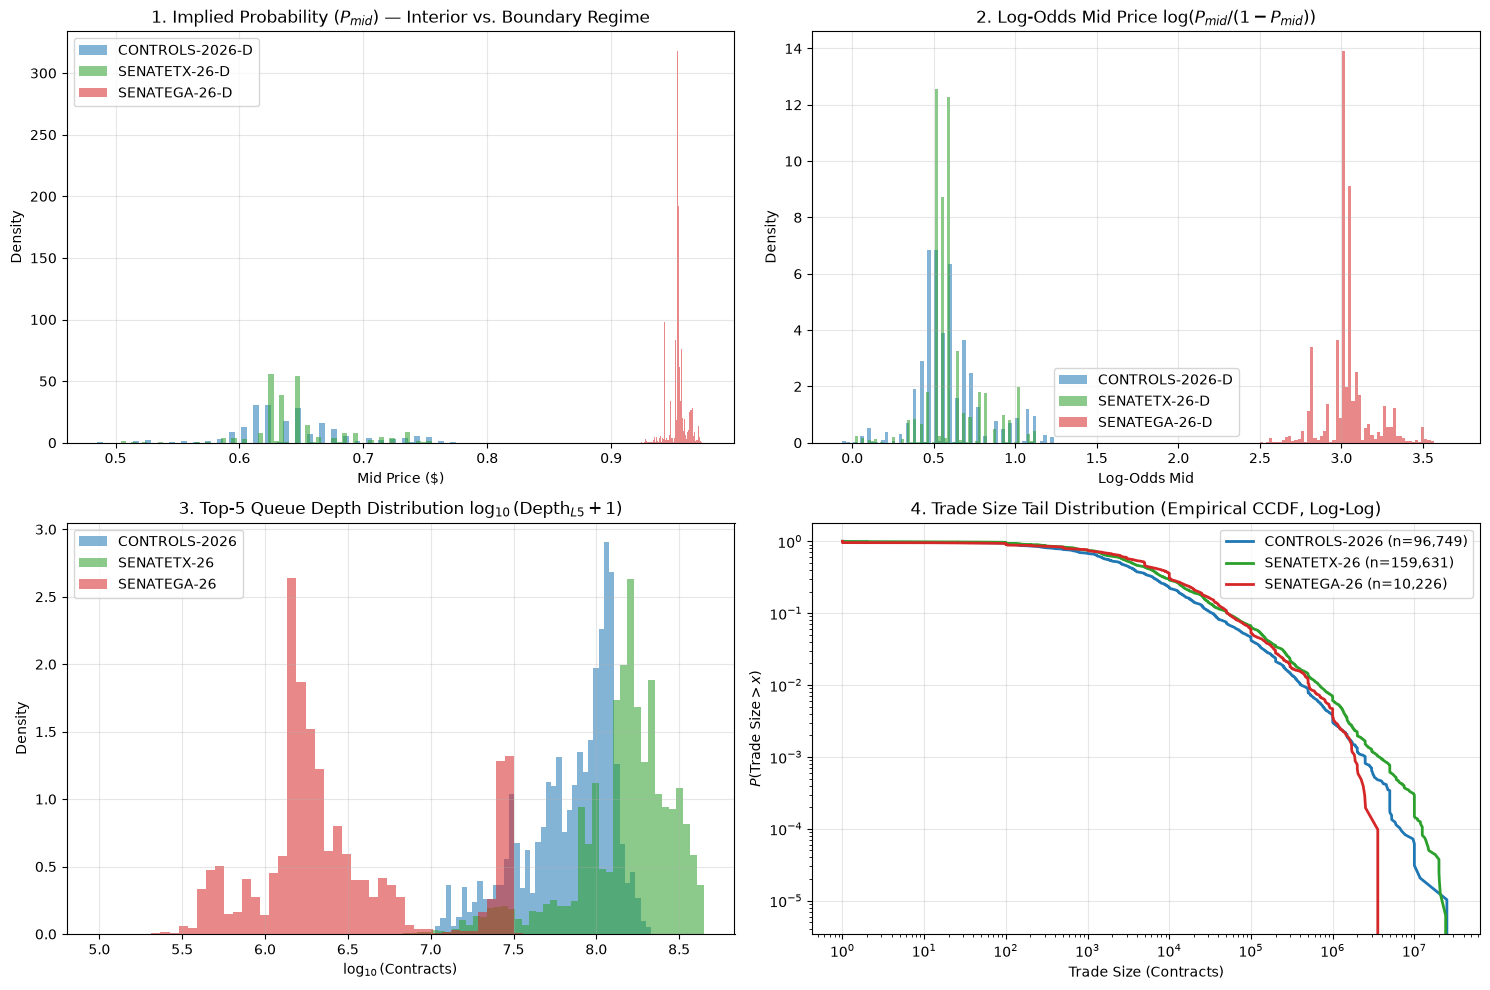

In [5]:
# Compute Mid-Price, Log-Odds Mid, L1/L5 Queue Depth, and Total Depth from the nested lists
PRICE_SCALE = 1000.0  # Your process_data.py scales prices by 1000 (0..1000 ticks)

df_micro = (
    df.filter(pl.col("best_bid").is_not_null() & pl.col("best_ask").is_not_null())
    .with_columns([
        ((pl.col("best_bid") + pl.col("best_ask")) / (2.0 * PRICE_SCALE)).alias("mid_prob"),
        (pl.col("spread") / PRICE_SCALE * 100.0).alias("spread_cents"),
        pl.col("bid_sizes").list.head(1).list.sum().alias("bid_l1_depth"),
        pl.col("ask_sizes").list.head(1).list.sum().alias("ask_l1_depth"),
        pl.col("bid_sizes").list.head(5).list.sum().alias("bid_l5_depth"),
        pl.col("ask_sizes").list.head(5).list.sum().alias("ask_l5_depth"),
    ])
    .with_columns([
        (pl.col("mid_prob").clip(0.001, 0.999)).alias("mid_prob_clipped"),
        (pl.col("bid_l5_depth") + pl.col("ask_l5_depth")).alias("total_l5_depth"),
    ])
    .with_columns([
        (pl.col("mid_prob_clipped") / (1.0 - pl.col("mid_prob_clipped"))).log().alias("log_odds_mid")
    ])
)

# Print summary table of microstructure regime metrics
regime_table = (
    df_micro.group_by(["contract", "ticker"])
    .agg([
        pl.col("mid_prob").median().round(3).alias("med_mid_price ($)"),
        pl.col("log_odds_mid").median().round(2).alias("med_log_odds"),
        pl.col("spread_cents").median().round(2).alias("med_spread (¢)"),
        pl.col("spread_cents").mean().round(2).alias("mean_spread (¢)"),
        (pl.col("bid_l1_depth") + pl.col("ask_l1_depth")).median().alias("med_L1_depth"),
        pl.col("total_l5_depth").median().alias("med_L5_depth"),
    ])
    .sort(["contract", "ticker"])
)
print("=== 3A. Microstructure Regime Summary Across Contracts ===")
print(regime_table)

# Trade size quantiles for determining V_min
trade_quantiles = (
    df.filter(pl.col("event_type") == "trade")
    .group_by(["contract", "ticker"])
    .agg([
        pl.len().alias("n_trades"),
        pl.col("trade_size").quantile(0.50).alias("p50_size"),
        pl.col("trade_size").quantile(0.75).alias("p75_size"),
        pl.col("trade_size").quantile(0.90).alias("p90_size"),
        pl.col("trade_size").quantile(0.95).alias("p95_size"),
        pl.col("trade_size").quantile(0.99).alias("p99_size"),
        pl.col("trade_size").max().alias("max_size"),
    ])
    .sort(["contract", "ticker"])
)
print("\n=== 3B. Single-Trade Volume Quantiles (Guides V_min) ===")
print(trade_quantiles)

# 4-Panel Plot for Report
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
contracts = ["CONTROLS-2026", "SENATETX-26", "SENATEGA-26"]
colors = {"CONTROLS-2026": "#1f77b4", "SENATETX-26": "#2ca02c", "SENATEGA-26": "#d62728"}

# Panel 1: Raw Mid-Price Distribution (Focusing on -D book for consistent party orientation, or all)
for c in contracts:
    sub = df_micro.filter((pl.col("contract") == c) & (pl.col("party") == "D"))["mid_prob"].to_numpy()
    axes[0, 0].hist(sub, bins=60, alpha=0.55, density=True, label=f"{c}-D", color=colors[c])
axes[0, 0].set_title("1. Implied Probability ($P_{mid}$) — Interior vs. Boundary Regime")
axes[0, 0].set_xlabel("Mid Price ($)")
axes[0, 0].set_ylabel("Density")
axes[0, 0].legend()

# Panel 2: Log-Odds Transformed Price
for c in contracts:
    sub = df_micro.filter((pl.col("contract") == c) & (pl.col("party") == "D"))["log_odds_mid"].to_numpy()
    axes[0, 1].hist(sub, bins=60, alpha=0.55, density=True, label=f"{c}-D", color=colors[c])
axes[0, 1].set_title("2. Log-Odds Mid Price $\\log(P_{mid} / (1 - P_{mid}))$")
axes[0, 1].set_xlabel("Log-Odds Mid")
axes[0, 1].set_ylabel("Density")
axes[0, 1].legend()

# Panel 3: Log10(L5 Total Queue Depth) Comparison
for c in contracts:
    sub = np.log10(df_micro.filter(pl.col("contract") == c)["total_l5_depth"].to_numpy() + 1.0)
    axes[1, 0].hist(sub, bins=50, alpha=0.55, density=True, label=c, color=colors[c])
axes[1, 0].set_title("3. Top-5 Queue Depth Distribution $\\log_{10}(\\text{Depth}_{L5} + 1)$")
axes[1, 0].set_xlabel("$\\log_{10}(\\text{Contracts})$")
axes[1, 0].set_ylabel("Density")
axes[1, 0].legend()

# Panel 4: Trade Size Empirical CCDF (Log-Log Tail Plot)
for c in contracts:
    sizes = np.sort(df.filter((pl.col("contract") == c) & (pl.col("event_type") == "trade"))["trade_size"].to_numpy())
    if len(sizes) > 0:
        ccdf = 1.0 - np.arange(1, len(sizes) + 1) / len(sizes)
        axes[1, 1].loglog(sizes, ccdf, label=f"{c} (n={len(sizes):,})", color=colors[c], lw=2)
axes[1, 1].set_title("4. Trade Size Tail Distribution (Empirical CCDF, Log-Log)")
axes[1, 1].set_xlabel("Trade Size (Contracts)")
axes[1, 1].set_ylabel("$P(\\text{Trade Size} > x)$")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

=== Goodness-of-Fit (Linearization R^2) Across Candidate Heavy-Tail Distributions ===
shape: (3, 7)
┌───────────────┬──────────────────┬───────────────────────┬─────────────────────┬─────────────────────────┬───────────┬─────────────────────────────────┐
│ contract      ┆ Pure_PowerLaw_R2 ┆ Truncated_PowerLaw_R2 ┆ LogNormal_Probit_R2 ┆ Weibull_StretchedExp_R2 ┆ TPL_alpha ┆ TPL_cutoff_1/lambda (contracts… │
│ ---           ┆ ---              ┆ ---                   ┆ ---                 ┆ ---                     ┆ ---       ┆ ---                             │
│ str           ┆ f64              ┆ f64                   ┆ f64                 ┆ f64                     ┆ f64       ┆ f64                             │
╞═══════════════╪══════════════════╪═══════════════════════╪═════════════════════╪═════════════════════════╪═══════════╪═════════════════════════════════╡
│ CONTROLS-2026 ┆ 0.963            ┆ 0.9788                ┆ 0.9535              ┆ 0.8006                  ┆ 0.704     ┆ 2540

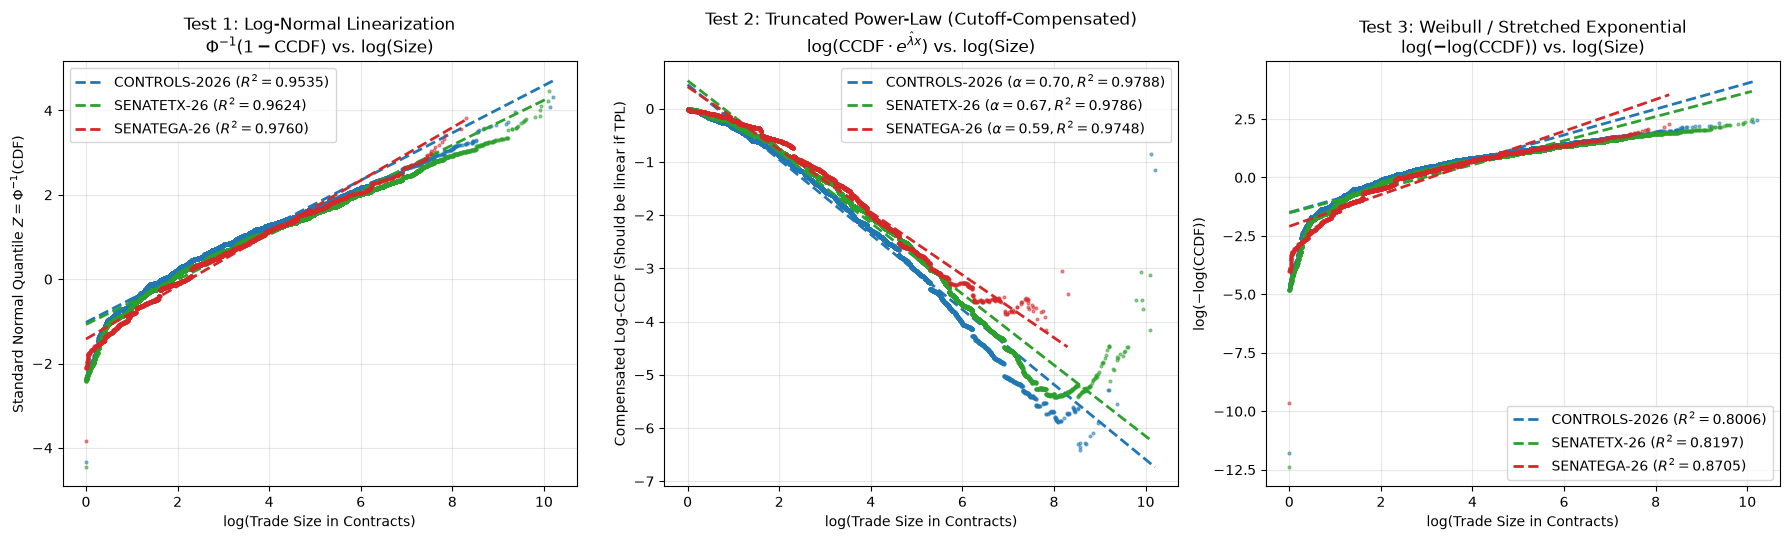

In [6]:
from scipy.stats import norm

QTY_SCALE = 1000.0
contracts = ["CONTROLS-2026", "SENATETX-26", "SENATEGA-26"]
colors = {"CONTROLS-2026": "#1f77b4", "SENATETX-26": "#2ca02c", "SENATEGA-26": "#d62728"}

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
r2_records = []

for c in contracts:
    raw_sizes = (
        df.filter((pl.col("contract") == c) & (pl.col("event_type") == "trade"))["trade_size"]
        .to_numpy() / QTY_SCALE
    )
    sizes = np.sort(raw_sizes[raw_sizes >= 1.0])
    n = len(sizes)
    
    # CDF, CCDF
    cdf = (np.arange(1, n + 1) - 0.5) / n
    ccdf = 1.0 - cdf
    
    # deduplicate
    u_sizes, idx = np.unique(sizes, return_index=True)
    u_cdf = cdf[idx]
    u_ccdf = ccdf[idx]
    log_x = np.log(u_sizes)
    
    # Log-Normal: Probit(CDF) vs log(x)
    # if log normal distribution, Phi^{-1}(1 - CCDF) and log(x) should be linear
    probit_y = norm.ppf(u_cdf)
    coef_log = np.polyfit(log_x, probit_y, 1)
    r2_log = np.corrcoef(log_x, probit_y)[0, 1] ** 2
    
    axes[0].plot(log_x, probit_y, ".", alpha=0.5, color=colors[c], markersize=4)
    axes[0].plot(log_x, np.polyval(coef_log, log_x), "--", color=colors[c], lw=2,
                 label=f"{c} ($R^2={r2_log:.4f}$)")
    
    # Truncated Power-Law:
    # log(CCDF) = c0 - alpha * log(x) - lambda * x
    X_tpl = np.column_stack([np.ones_like(log_x), -log_x, -u_sizes])
    params_tpl, _, _, _ = np.linalg.lstsq(X_tpl, np.log(u_ccdf), rcond=None)
    c0_hat, alpha_hat, lam_hat = params_tpl
    lam_hat = max(lam_hat, 0.0)  # lambda >= 0

    compensated_log_ccdf = np.log(u_ccdf) + (lam_hat * u_sizes)
    r2_tpl = np.corrcoef(log_x, compensated_log_ccdf)[0, 1] ** 2
    
    axes[1].plot(log_x, compensated_log_ccdf, ".", alpha=0.5, color=colors[c], markersize=4)
    axes[1].plot(log_x, c0_hat - alpha_hat * log_x, "--", color=colors[c], lw=2,
                 label=f"{c} ($\\alpha={alpha_hat:.2f}, R^2={r2_tpl:.4f}$)")

    # Weibul Stretched Exponential
    # if CCDF = exp(-(x/beta)^gamma), then log(-log(CCDF)) vs log(x) should be linear
    weibull_y = np.log(-np.log(u_ccdf))
    coef_wb = np.polyfit(log_x, weibull_y, 1)
    r2_wb = np.corrcoef(log_x, weibull_y)[0, 1] ** 2
    
    axes[2].plot(log_x, weibull_y, ".", alpha=0.5, color=colors[c], markersize=4)
    axes[2].plot(log_x, np.polyval(coef_wb, log_x), "--", color=colors[c], lw=2,
                 label=f"{c} ($R^2={r2_wb:.4f}$)")
    
    # Pure Power-Law
    r2_pure_pl = np.corrcoef(log_x, np.log(u_ccdf))[0, 1] ** 2
    r2_records.append({
        "contract": c,
        "Pure_PowerLaw_R2": round(r2_pure_pl, 4),
        "Truncated_PowerLaw_R2": round(r2_tpl, 4),
        "LogNormal_Probit_R2": round(r2_log, 4),
        "Weibull_StretchedExp_R2": round(r2_wb, 4),
        "TPL_alpha": round(alpha_hat, 3),
        "TPL_cutoff_1/lambda (contracts)": round(1.0 / lam_hat, 0) if lam_hat > 0 else None,
    })

axes[0].set_title("Test 1: Log-Normal Linearization\n$\\Phi^{-1}(1 - \\text{CCDF})$ vs. $\\log(\\text{Size})$")
axes[0].set_xlabel("$\\log(\\text{Trade Size in Contracts})$")
axes[0].set_ylabel("Standard Normal Quantile $Z = \\Phi^{-1}(\\text{CDF})$")
axes[0].legend()

axes[1].set_title("Test 2: Truncated Power-Law (Cutoff-Compensated)\n$\\log(\\text{CCDF} \\cdot e^{\\hat{\\lambda} x})$ vs. $\\log(\\text{Size})$")
axes[1].set_xlabel("$\\log(\\text{Trade Size in Contracts})$")
axes[1].set_ylabel("Compensated Log-CCDF (Should be linear if TPL)")
axes[1].legend()

axes[2].set_title("Test 3: Weibull / Stretched Exponential\n$\\log(-\\log(\\text{CCDF}))$ vs. $\\log(\\text{Size})$")
axes[2].set_xlabel("$\\log(\\text{Trade Size in Contracts})$")
axes[2].set_ylabel("$\\log(-\\log(\\text{CCDF}))$")
axes[2].legend()

plt.tight_layout()

print("=== Goodness-of-Fit (Linearization R^2) Across Candidate Heavy-Tail Distributions ===")
print(pl.DataFrame(r2_records))

In [7]:
df_verify = (
    df.with_columns([
        pl.col("bid_sizes").list.sum().alias("total_bid_qty"),
        pl.col("ask_sizes").list.sum().alias("total_ask_qty"),
        pl.col("bid_sizes").list.head(1).list.sum().alias("bid_l1_qty"),
        pl.col("ask_sizes").list.head(1).list.sum().alias("ask_l1_qty"),
    ])
    .with_columns([
        # step j: depth[j] - depth[j-1]
        # (depleted qty) = depth[j-1] - depth[j] > 0
        (pl.col("total_bid_qty").shift(1).over("chunk_id") - pl.col("total_bid_qty")).alias("bid_depleted_at_step"),
        (pl.col("total_ask_qty").shift(1).over("chunk_id") - pl.col("total_ask_qty")).alias("ask_depleted_at_step"),
        (pl.col("bid_l1_qty").shift(1).over("chunk_id") - pl.col("bid_l1_qty")).alias("bid_l1_depleted_at_step"),
        (pl.col("ask_l1_qty").shift(1).over("chunk_id") - pl.col("ask_l1_qty")).alias("ask_l1_depleted_at_step"),
        pl.col("best_bid").shift(1).over("chunk_id").alias("prev_best_bid"),
        pl.col("best_ask").shift(1).over("chunk_id").alias("prev_best_ask"),
    ])
    .with_columns([
        pl.col("event_type").shift(1).over("chunk_id").alias("prev1_type"),
        pl.col("delta_t_ms").alias("dt_from_prev1_ms"),
        pl.col("bid_depleted_at_step").shift(1).over("chunk_id").alias("prev1_bid_dep"),
        pl.col("ask_depleted_at_step").shift(1).over("chunk_id").alias("prev1_ask_dep"),
        (
            pl.col("bid_depleted_at_step").shift(1).over("chunk_id") +
            pl.when(pl.col("event_type").shift(2).over("chunk_id") == "delta_book")
              .then(pl.col("bid_depleted_at_step").shift(2).over("chunk_id")).otherwise(0)
        ).alias("prev12_bid_dep"),
        (
            pl.col("ask_depleted_at_step").shift(1).over("chunk_id") +
            pl.when(pl.col("event_type").shift(2).over("chunk_id") == "delta_book")
              .then(pl.col("ask_depleted_at_step").shift(2).over("chunk_id")).otherwise(0)
        ).alias("prev12_ask_dep"),
        pl.col("event_type").shift(-1).over("chunk_id").alias("next1_type"),
        pl.col("delta_t_ms").shift(-1).over("chunk_id").alias("dt_to_next1_ms"),
        pl.col("bid_depleted_at_step").shift(-1).over("chunk_id").alias("next1_bid_dep"),
        pl.col("ask_depleted_at_step").shift(-1).over("chunk_id").alias("next1_ask_dep"),
    ])
)

trades_match = (
    df_verify.filter(pl.col("event_type") == "trade")
    .with_columns([
        pl.when(pl.col("taker_side") == "yes_taker")
          .then(pl.col("prev1_ask_dep"))
          .otherwise(pl.col("prev1_bid_dep"))
          .alias("prev1_matched_dep"),
        pl.when(pl.col("taker_side") == "yes_taker")
          .then(pl.col("prev12_ask_dep"))
          .otherwise(pl.col("prev12_bid_dep"))
          .alias("prev12_matched_dep"),
        pl.when(pl.col("taker_side") == "yes_taker")
          .then(pl.col("next1_ask_dep"))
          .otherwise(pl.col("next1_bid_dep"))
          .alias("next1_matched_dep"),
        pl.when(pl.col("taker_side") == "yes_taker")
          .then(pl.col("trade_price") == pl.col("prev_best_ask"))
          .otherwise(pl.col("trade_price") == pl.col("prev_best_bid"))
          .alias("price_matches_l1"),
    ])
    .with_columns([
        ((pl.col("prev1_type") == "delta_book") & (pl.col("prev1_matched_dep") == pl.col("trade_size"))).alias("exact_match_prev1"),
        ((pl.col("prev1_type") == "delta_book") & (
            (pl.col("prev1_matched_dep") == pl.col("trade_size")) |
            (pl.col("prev12_matched_dep") == pl.col("trade_size"))
        )).alias("exact_match_prev1_or_2"),
        ((pl.col("next1_type") == "delta_book") & (pl.col("next1_matched_dep") == pl.col("trade_size"))).alias("exact_match_next1"),
    ])
)

exact_summary = (
    trades_match.group_by("contract")
    .agg([
        pl.len().alias("total_trades"),
        pl.col("exact_match_prev1").sum().alias("n_exact_prev1"),
        (pl.col("exact_match_prev1").mean() * 100).round(2).alias("pct_exact_prev1 (%)"),
        (pl.col("exact_match_prev1_or_2").mean() * 100).round(2).alias("pct_exact_prev1_2 (%)"),
        ((pl.col("exact_match_prev1") & pl.col("price_matches_l1")).mean() * 100).round(2).alias("pct_exact_prev1_&_px (%)"),
        pl.col("exact_match_next1").sum().alias("n_exact_next1"),
        (pl.col("exact_match_next1").mean() * 100).round(2).alias("pct_exact_next1 (%)"),
        pl.col("dt_from_prev1_ms").filter(pl.col("exact_match_prev1")).median().round(4).alias("matched_prev1_med_dt_ms"),
        pl.col("dt_from_prev1_ms").filter(pl.col("exact_match_prev1")).quantile(0.99).round(4).alias("matched_prev1_p99_dt_ms"),
    ])
    .sort("contract")
)

print("=== 4A (Rigorous). Exact Quantity, Side & Price Match Between 'trade' and Adjacent 'delta_book' ===")
print(exact_summary)

print("\n=== 4B (Rigorous). Line-by-Line Verification of 10 Large Trades (>= 100 Contracts, i.e., trade_size >= 100,000) ===")
large_samples = (
    trades_match.filter((pl.col("contract") == "CONTROLS-2026") & (pl.col("trade_size") >= 100_000))
    .select([
        "ticker", "chunk_id", "event_seq", "taker_side", "trade_price", "prev_best_bid", "prev_best_ask",
        "trade_size", "prev1_matched_dep", "next1_matched_dep", "dt_from_prev1_ms", "exact_match_prev1"
    ])
    .head(10)
)
print(large_samples)

=== 4A (Rigorous). Exact Quantity, Side & Price Match Between 'trade' and Adjacent 'delta_book' ===
shape: (3, 10)
┌───────────────┬──────────────┬───────────────┬───────────────┬───────────────┬───────────────┬───────────────┬───────────────┬───────────────┬───────────────┐
│ contract      ┆ total_trades ┆ n_exact_prev1 ┆ pct_exact_pre ┆ pct_exact_pre ┆ pct_exact_pre ┆ n_exact_next1 ┆ pct_exact_nex ┆ matched_prev1 ┆ matched_prev1 │
│ ---           ┆ ---          ┆ ---           ┆ v1 (%)        ┆ v1_2 (%)      ┆ v1_&_px (%)   ┆ ---           ┆ t1 (%)        ┆ _med_dt_ms    ┆ _p99_dt_ms    │
│ str           ┆ u32          ┆ u32           ┆ ---           ┆ ---           ┆ ---           ┆ u32           ┆ ---           ┆ ---           ┆ ---           │
│               ┆              ┆               ┆ f64           ┆ f64           ┆ f64           ┆               ┆ f64           ┆ f32           ┆ f32           │
╞═══════════════╪══════════════╪═══════════════╪═══════════════╪═══════════════╪

In [8]:
# Check 5: Cross-Book Lead-Lag Analysis between Economically Equivalent Pairs:
# Pair 1 (Pro-Republican): R_yes  <-->  D_no
# Pair 2 (Pro-Democrat):   D_yes  <-->  R_no

LARGE_TRADE_FLOOR = 50  # Minimum trade size to consider an "initiator" impulse

trades_all = (
    df.filter(pl.col("event_type") == "trade")
    .select(["contract", "party", "timestamp_ns", "taker_side", "trade_size"])
    .sort("timestamp_ns")
)

def analyze_cross_book_lag(contract_name: str, min_size: int = LARGE_TRADE_FLOOR):
    sub = trades_all.filter(pl.col("contract") == contract_name)
    
    # Split into the 4 directional trade streams
    r_yes = sub.filter((pl.col("party") == "R") & (pl.col("taker_side") == "yes_taker")).sort("timestamp_ns")
    d_no  = sub.filter((pl.col("party") == "D") & (pl.col("taker_side") == "no_taker")).sort("timestamp_ns")
    d_yes = sub.filter((pl.col("party") == "D") & (pl.col("taker_side") == "yes_taker")).sort("timestamp_ns")
    r_no  = sub.filter((pl.col("party") == "R") & (pl.col("taker_side") == "no_taker")).sort("timestamp_ns")
    
    # Direction A: Large R_yes -> how soon does next D_no occur?
    r_yes_large = r_yes.filter(pl.col("trade_size") >= min_size)
    d_yes_large = d_yes.filter(pl.col("trade_size") >= min_size)
    d_no_large  = d_no.filter(pl.col("trade_size") >= min_size)
    r_no_large  = r_no.filter(pl.col("trade_size") >= min_size)

    pairs = [
        ("R_yes -> D_no", r_yes_large, d_no),
        ("D_no  -> R_yes", d_no_large, r_yes),
        ("D_yes -> R_no", d_yes_large, r_no),
        ("R_no  -> D_yes", r_no_large, d_yes),
    ]
    
    rows = []
    for label, leader_df, follower_df in pairs:
        if leader_df.height == 0 or follower_df.height == 0:
            continue
        
        # Find the very next trade on the paired book strictly after leader timestamp
        joined = leader_df.join_asof(
            follower_df.select([
                pl.col("timestamp_ns").alias("follower_ts_ns"),
                pl.col("trade_size").alias("follower_size")
            ]),
            left_on="timestamp_ns",
            right_on="follower_ts_ns",
            strategy="forward"
        ).with_columns([
            ((pl.col("follower_ts_ns") - pl.col("timestamp_ns")) / 1e9).alias("lag_sec")
        ])
        
        n_total = joined.height
        rows.append({
            "contract": contract_name,
            "pair": label,
            "n_leader_trades": n_total,
            "prob_<=0.5s (%)": round(joined.filter(pl.col("lag_sec") <= 0.5).height / n_total * 100, 1),
            "prob_<=1.0s (%)": round(joined.filter(pl.col("lag_sec") <= 1.0).height / n_total * 100, 1),
            "prob_<=3.0s (%)": round(joined.filter(pl.col("lag_sec") <= 3.0).height / n_total * 100, 1),
            "prob_<=5.0s (%)": round(joined.filter(pl.col("lag_sec") <= 5.0).height / n_total * 100, 1),
            "prob_<=10.0s (%)": round(joined.filter(pl.col("lag_sec") <= 10.0).height / n_total * 100, 1),
            "median_lag (s)": round(joined["lag_sec"].median(), 2) if joined["lag_sec"].drop_nulls().len() > 0 else None,
        })
    return pl.DataFrame(rows)

lag_tables = [analyze_cross_book_lag(c) for c in ["CONTROLS-2026", "SENATETX-26", "SENATEGA-26"]]
lag_summary = pl.concat([t for t in lag_tables if t.height > 0])
print(f"=== 5. Cross-Book Lead-Lag Response Probability (Leader Trade >= {LARGE_TRADE_FLOOR} Contracts) ===")
print(lag_summary)

=== 5. Cross-Book Lead-Lag Response Probability (Leader Trade >= 50 Contracts) ===
shape: (12, 9)
┌───────────────┬────────────────┬─────────────────┬─────────────────┬─────────────────┬─────────────────┬─────────────────┬──────────────────┬────────────────┐
│ contract      ┆ pair           ┆ n_leader_trades ┆ prob_<=0.5s (%) ┆ prob_<=1.0s (%) ┆ prob_<=3.0s (%) ┆ prob_<=5.0s (%) ┆ prob_<=10.0s (%) ┆ median_lag (s) │
│ ---           ┆ ---            ┆ ---             ┆ ---             ┆ ---             ┆ ---             ┆ ---             ┆ ---              ┆ ---            │
│ str           ┆ str            ┆ i64             ┆ f64             ┆ f64             ┆ f64             ┆ f64             ┆ f64              ┆ f64            │
╞═══════════════╪════════════════╪═════════════════╪═════════════════╪═════════════════╪═════════════════╪═════════════════╪══════════════════╪════════════════╡
│ CONTROLS-2026 ┆ R_yes -> D_no  ┆ 43612           ┆ 0.5             ┆ 1.1             ┆ 3.5     

=== 6. Bucketed Price-Impact R² (%) — 60s buckets, D & R books pooled ===
shape: (3, 9)
┌───────────────┬───────────┬──────────────┬──────────────┬────────────────┬──────────────────┬──────────────┬──────────────────┬─────────────────────┐
│ contract      ┆ n_buckets ┆ OFI_total(b) ┆ OFI_limit(b) ┆ TFI(b) [Trades ┆ OFI_limit(b) →   ┆ TFI(b) →     ┆ OFI_limit(b) →   ┆ TFI(b) → TFI(b+1)   │
│ ---           ┆ ---       ┆ ---          ┆ [Limit Only] ┆ Only]          ┆ ΔP_mid(b+1)      ┆ ΔP_mid(b+1)  ┆ TFI(b+1)         ┆ ---                 │
│ str           ┆ i64       ┆ f64          ┆ ---          ┆ ---            ┆ ---              ┆ ---          ┆ ---              ┆ f64                 │
│               ┆           ┆              ┆ f64          ┆ f64            ┆ f64              ┆ f64          ┆ f64              ┆                     │
╞═══════════════╪═══════════╪══════════════╪══════════════╪════════════════╪══════════════════╪══════════════╪══════════════════╪═════════════════════╡


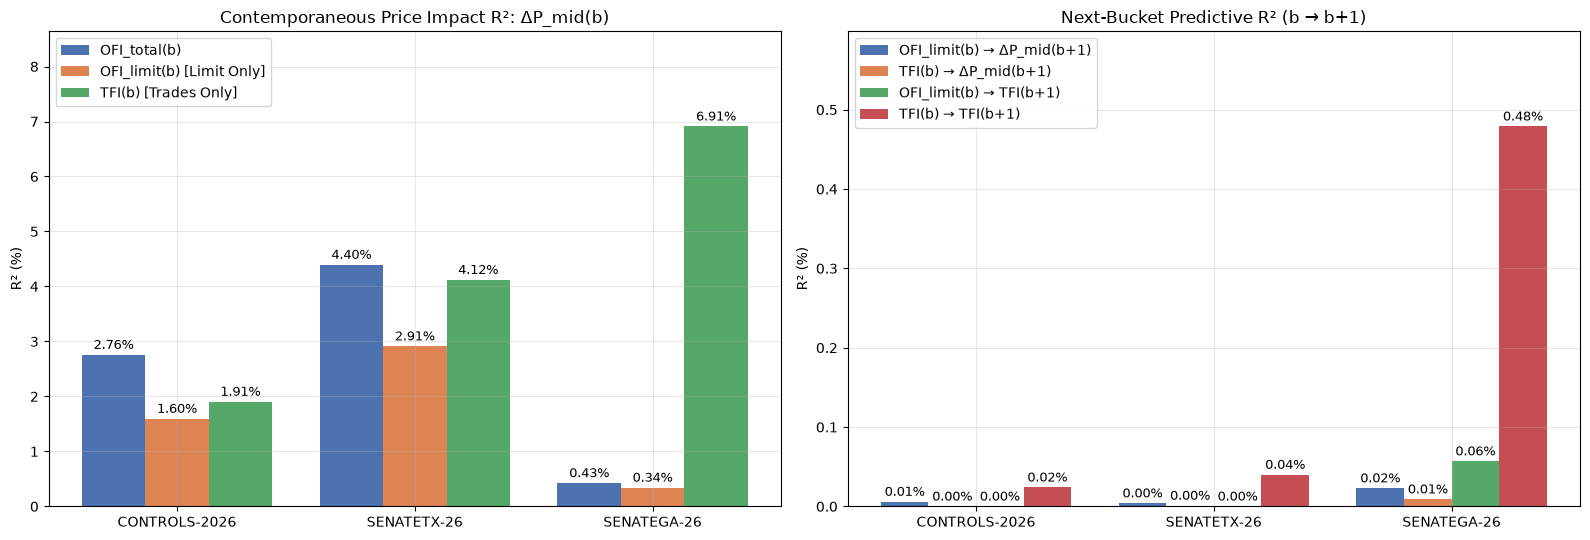

In [9]:
# Check 6: Bucketed OFI / TFI price-impact regressions (Cont-Kukanov-Stoikov style)
#   OFI_total(b) : L1 order-flow imbalance over bucket b (limit adds/cancels + trade depletion)
#   TFI(b)       : signed taker volume (yes_taker = +, no_taker = -)
#   OFI_limit(b) : OFI_total(b) with trade-driven L1 depletion removed (limit orders only)
#   dP_mid(b)    : mid(end of b) - mid(end of b-1), in cents
BUCKET_SEC = 60  # try 10 / 60 / 300; empty buckets count as zero flow
BUCKET_NS = int(BUCKET_SEC * 1e9)
KEY = ["contract", "ticker", "segment"]  # one continuous book stream
contracts = ["CONTROLS-2026", "SENATETX-26", "SENATEGA-26"]

bid1 = pl.col("bid_sizes").list.first().fill_null(0).cast(pl.Float64)
ask1 = pl.col("ask_sizes").list.first().fill_null(0).cast(pl.Float64)

ev = (
    df.sort(KEY + ["timestamp_ns", "event_seq"])
    .with_columns(
        # book state is unchanged on trade rows -> carry it forward
        pl.col("best_bid").forward_fill().over(KEY).alias("bb"),
        pl.col("best_ask").forward_fill().over(KEY).alias("ba"),
        bid1.alias("bq"),
        ask1.alias("aq"),
    )
    .with_columns(
        pl.when(pl.col("event_type") == "trade").then(None).otherwise(pl.col("bq")).forward_fill().over(KEY).alias("bq"),
        pl.when(pl.col("event_type") == "trade").then(None).otherwise(pl.col("aq")).forward_fill().over(KEY).alias("aq"),
    )
    .with_columns(
        pl.col("bb").shift(1).over(KEY).alias("p_bb"),
        pl.col("ba").shift(1).over(KEY).alias("p_ba"),
        pl.col("bq").shift(1).over(KEY).alias("p_bq"),
        pl.col("aq").shift(1).over(KEY).alias("p_aq"),
        pl.when(pl.col("event_type") == "trade").then(
            pl.when(pl.col("taker_side") == "yes_taker").then(pl.col("trade_size")).otherwise(-pl.col("trade_size"))
        ).otherwise(0).cast(pl.Float64).alias("signed_vol"),
    )
    .with_columns(
        # CKS L1 OFI per event
        (
            (pl.when(pl.col("bb") >= pl.col("p_bb")).then(pl.col("bq")).otherwise(0.0)
             - pl.when(pl.col("bb") <= pl.col("p_bb")).then(pl.col("p_bq")).otherwise(0.0))
            - (pl.when(pl.col("ba") <= pl.col("p_ba")).then(pl.col("aq")).otherwise(0.0)
               - pl.when(pl.col("ba") >= pl.col("p_ba")).then(pl.col("p_aq")).otherwise(0.0))
        ).fill_null(0.0).alias("ofi_step"),
        # trade depletion of L1, capped by the queue it hits (buys eat ask, sells eat bid)
        pl.when(pl.col("signed_vol") > 0).then(pl.min_horizontal("signed_vol", "p_aq"))
          .when(pl.col("signed_vol") < 0).then(-pl.min_horizontal(-pl.col("signed_vol"), pl.col("p_bq")))
          .otherwise(0.0).fill_null(0.0).alias("trade_dep"),
        ((pl.col("bb") + pl.col("ba")) / (2.0 * PRICE_SCALE) * 100.0).alias("mid_c"),
        (pl.col("timestamp_ns") // BUCKET_NS).alias("bucket"),
    )
)

# Aggregate per bucket, then reindex onto a full bucket grid (empty bucket = zero flow, unchanged mid)
agg = ev.group_by(KEY + ["bucket"]).agg(
    pl.col("ofi_step").sum().alias("OFI_total"),
    (pl.col("ofi_step").sum() - pl.col("trade_dep").sum()).alias("OFI_limit"),
    pl.col("signed_vol").sum().alias("TFI"),
    pl.col("mid_c").drop_nulls().last().alias("mid_end"),
)
grid = (
    agg.group_by(KEY)
    .agg(pl.int_ranges(pl.col("bucket").min(), pl.col("bucket").max() + 1).first().alias("bucket"))
    .explode("bucket")
)
buckets = (
    grid.join(agg, on=KEY + ["bucket"], how="left")
    .sort(KEY + ["bucket"])
    .with_columns(pl.col(["OFI_total", "OFI_limit", "TFI"]).fill_null(0.0))
    .with_columns(pl.col("mid_end").forward_fill().over(KEY))
    .with_columns(pl.col("mid_end").diff().over(KEY).alias("dP"))
    .with_columns(
        pl.col("dP").shift(-1).over(KEY).alias("dP_next"),
        pl.col("TFI").shift(-1).over(KEY).alias("TFI_next"),
    )
)

def r2(sub: pl.DataFrame, x: str, y: str) -> float:
    s = sub.select([x, y]).drop_nulls().filter(pl.col(x).is_finite() & pl.col(y).is_finite())
    if s.height < 3 or s[x].std() == 0 or s[y].std() == 0:
        return float("nan")
    return float(np.corrcoef(s[x].to_numpy(), s[y].to_numpy())[0, 1] ** 2) * 100.0

contemp_specs = [("OFI_total", "dP", "OFI_total(b)"),
                 ("OFI_limit", "dP", "OFI_limit(b) [Limit Only]"),
                 ("TFI", "dP", "TFI(b) [Trades Only]")]
pred_specs = [("OFI_limit", "dP_next", "OFI_limit(b) → ΔP_mid(b+1)"),
              ("TFI", "dP_next", "TFI(b) → ΔP_mid(b+1)"),
              ("OFI_limit", "TFI_next", "OFI_limit(b) → TFI(b+1)"),
              ("TFI", "TFI_next", "TFI(b) → TFI(b+1)")]

rows = []
for c in contracts:
    sub = buckets.filter(pl.col("contract") == c)
    rows.append({"contract": c, "n_buckets": sub.height,
                 **{lab: round(r2(sub, x, y), 3) for x, y, lab in contemp_specs + pred_specs}})
r2_table = pl.DataFrame(rows)
print(f"=== 6. Bucketed Price-Impact R² (%) — {BUCKET_SEC}s buckets, D & R books pooled ===")
print(r2_table)

def grouped_bars(ax, specs, title, ylabel="R² (%)"):
    x = np.arange(len(contracts))
    width = 0.8 / len(specs)
    for i, (_, _, lab) in enumerate(specs):
        vals = r2_table[lab].to_numpy()
        bars = ax.bar(x + (i - (len(specs) - 1) / 2) * width, vals, width, label=lab)
        ax.bar_label(bars, labels=[f"{v:.2f}%" for v in vals], fontsize=9, padding=2)
    ax.set_xticks(x, contracts)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, np.nanmax(r2_table.select([s[2] for s in specs]).to_numpy()) * 1.25)
    ax.legend(loc="upper left")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
grouped_bars(axes[0], contemp_specs, "Contemporaneous Price Impact R²: ΔP_mid(b)")
grouped_bars(axes[1], pred_specs, "Next-Bucket Predictive R² (b → b+1)")
plt.tight_layout()
plt.show()